<a href="https://colab.research.google.com/github/sara-velmont/Apendice_de_tesis_Un_modelo_de_W-S_en_HQ/blob/main/Modelo_de_W_S_en_HQ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Creación de de los HQC y el HQ regular propuesto para el modelo

In [1]:
import itertools
import random
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# 6 Sustancias
V1 = {"A", "B", "C", "D", "E", "F"}
#Conjunto potencia
P1 = [set(c) for i in range(1, len(V1)+1) for c in itertools.combinations(sorted(V1), i)]

In [3]:
P1.pop(62)

{'A', 'B', 'C', 'D', 'E', 'F'}

In [4]:
E1 = [(X, Y) for X in P1 for Y in P1 if X != Y and X.isdisjoint(Y)]
E1 = {frozenset([frozenset(X), frozenset(Y)]) for X, Y in E1}
E1 = [(set(pair.pop()), set(pair.pop())) for pair in map(set, E1)]

In [5]:
def set_to_label(s):
    return ''.join(sorted(s))
#N=6

Hipernodos1 = [set_to_label(s) for s in P1]
Reacciones_c1 = [(set_to_label(x), set_to_label(y)) for x, y in E1 if x.isdisjoint(y)]


# Crear grafo
G1 = nx.Graph()
G1.add_nodes_from(Hipernodos1)
G1.add_edges_from(Reacciones_c1)

#Matriz de adyacencia del hipergrafo completo
A1 = nx.adjacency_matrix(G1).todense()
hipernodos1 = sorted(G1.nodes())

In [6]:
A1_R = np.copy(A1)

# poner ceros en filas y columnas
A1_R[0:6, 0:6] = 0



#Bloque 3x3
A1_R[21:62, 21:62] = 0


#Bloques superiores a 2x3 y transpuestos

A1_R[41:62, 0:21] = 0

# mantener simetría
A1_R[0:21, 41:62] = 0

Visualización del HQ regular

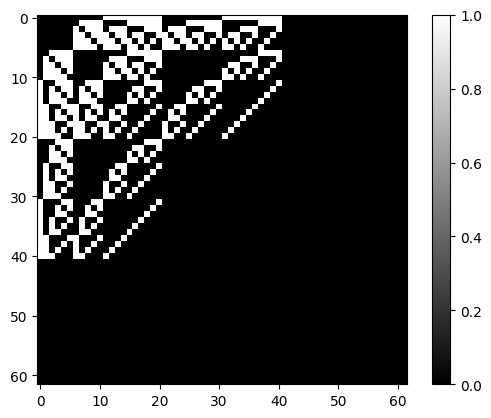

In [7]:
plt.imshow(A1_R, cmap='gray')
plt.colorbar()
plt.show()

Creación de proyección 1 con las matrices de adyacencia

In [8]:
GC_6 = nx.from_numpy_array(A1)

In [9]:
G6_R = nx.from_numpy_array(A1_R)

Lista de enlaces del completo para la reconexión

In [10]:
#Lista de enlaces válida
edges_v = list(GC_6.edges())

#Diccioario de aristas:
edges_v = {n: set(GC_6.neighbors(n)) for n in GC_6.nodes()}

Verificación de enlaces

In [11]:
print("Enlaces iniciales completo:", GC_6.number_of_edges())
print("Enlaces iniciales regular:", G6_R.number_of_edges())

Enlaces iniciales completo: 301
Enlaces iniciales regular: 225


Algoritmo con restricciones de reconexión. Impide que se seleccionen enlaces "puente" que podrían desconectar el grafo.

In [12]:
#Algoritmo propuesto

def constrained_rewire(G, edges_v, p):

    H = G.copy()
    edges = list(H.edges())


    for (u,v) in edges:

        # recalcular puentes
        bridges = set(nx.bridges(H))

        if (u,v) in bridges or (v,u) in bridges:
            continue

        if random.random() < p:

            vecinos = set(H.neighbors(u))
            candidatos = edges_v.get(u, set()) #Considerando todas los posibles enlaces del completo

            posibles = candidatos - vecinos - {u}

            if not posibles:
                continue

            w = random.choice(tuple(posibles))

            H.remove_edge(u,v)
            H.add_edge(u,w)

    return H

In [18]:
arreglo = np.logspace(-4,0,20)
corridas = 100

Se fija el parámetro q=0.5

In [14]:
#Propuesta de cambio de orden en los enlaces 50% cambiados

edges = list(G6_R.edges())

edges_random = [
    (u, v) if random.random() < 0.5 else (v, u)
    for (u, v) in edges]

In [15]:
print(edges_random)

[(11, 0), (12, 0), (13, 0), (14, 0), (15, 0), (0, 16), (0, 17), (18, 0), (0, 19), (20, 0), (31, 0), (32, 0), (0, 33), (0, 34), (0, 35), (36, 0), (37, 0), (0, 38), (0, 39), (40, 0), (7, 1), (8, 1), (9, 1), (10, 1), (15, 1), (1, 16), (17, 1), (1, 18), (1, 19), (20, 1), (1, 25), (1, 26), (27, 1), (28, 1), (1, 29), (30, 1), (37, 1), (1, 38), (1, 39), (40, 1), (6, 2), (8, 2), (9, 2), (2, 10), (12, 2), (2, 13), (2, 14), (18, 2), (19, 2), (2, 20), (2, 22), (23, 2), (24, 2), (2, 28), (2, 29), (2, 30), (2, 34), (2, 35), (2, 36), (2, 40), (6, 3), (3, 7), (3, 9), (10, 3), (3, 11), (13, 3), (3, 14), (3, 16), (17, 3), (20, 3), (21, 3), (23, 3), (24, 3), (26, 3), (27, 3), (3, 30), (32, 3), (33, 3), (36, 3), (39, 3), (6, 4), (4, 7), (8, 4), (10, 4), (11, 4), (12, 4), (4, 14), (15, 4), (4, 17), (4, 19), (4, 21), (4, 22), (4, 24), (25, 4), (27, 4), (29, 4), (4, 31), (33, 4), (4, 35), (4, 38), (6, 5), (7, 5), (5, 8), (5, 9), (5, 11), (12, 5), (5, 13), (5, 15), (5, 16), (18, 5), (5, 21), (22, 5), (5, 23)

Prueba de que los grafos son isomorfos

In [16]:
#Prueba de que son los mismos enlaces
G1 = nx.Graph(edges)
G2 = nx.Graph(edges_random)

print(nx.is_isomorphic(G1, G2))

True


Se fija el orden de los nodos para que mantengan la correspondencia con los hipernodos del HQ.

In [17]:
nodos = sorted(G1.nodes())

A_Rp1 = nx.to_numpy_array(G1, nodelist=nodos)
A_Rp2 = nx.to_numpy_array(G2, nodelist=nodos)

Recreación del experimento de W-S con el algoritmo propuesto para HQ.

In [19]:
#Valores iniciales
C0 = nx.average_clustering(G2)
L0 = nx.average_shortest_path_length(G2)

In [20]:
Clus_valores = []
Dist_valores = []

for p in arreglo:

    Clus_sum = 0
    Dist_sum = 0

    for _ in range(corridas):

        GWS = constrained_rewire(G2, edges_v, p)

        C = nx.average_clustering(GWS)
        L = nx.average_shortest_path_length(GWS)

        Clus_sum += C
        Dist_sum += L

    Clus_prom = Clus_sum / corridas
    Dist_prom = Dist_sum / corridas


    Clus_valores.append(Clus_prom / C0)
    Dist_valores.append(Dist_prom / L0)


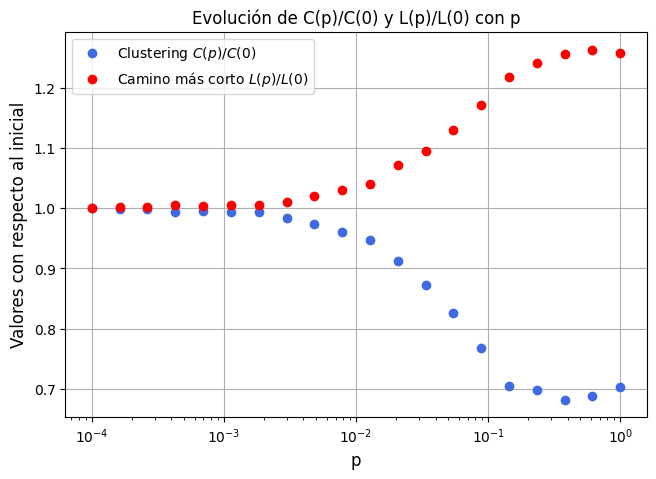

In [ ]:
plt.figure(figsize=(7.5,5))
plt.semilogx(arreglo, Clus_valores, 'o',
             color='royalblue',
             markersize=6,
             label=r'Clustering $C(p)/C(0)$')

plt.semilogx(arreglo, Dist_valores, 'o',
             color='red',
             markersize=6,
             label=r'Camino más corto $L(p)/L(0)$')

plt.xlabel('p', fontsize=12)
plt.ylabel('Valores con respecto al inicial', fontsize=12)
plt.title('Evolución de C(p)/C(0) y L(p)/L(0) con p')


plt.legend()
plt.grid()
plt.show()